In [4]:
import zipfile

with zipfile.ZipFile("CNN_Fruit_Project.ipynb.zip", "r") as zip_ref:
    zip_ref.extractall("fruit_project")

print("Extracted Successfully")

Extracted Successfully


In [7]:
train_path = r"fruit_project/dataset/dataset/train"
test_path  = r"fruit_project/dataset/dataset/test"

print(os.path.exists(train_path))
print(os.path.exists(test_path))

True
True


In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_dir = "fruit_project/dataset/dataset/train"
test_dir  = "fruit_project/dataset/dataset/test"

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(128,128),
    batch_size=32,
    class_mode='categorical'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(128,128),
    batch_size=32,
    class_mode='categorical'
)

Found 10901 images belonging to 6 classes.
Found 2698 images belonging to 6 classes.


In [9]:
print(train_generator.class_indices)

{'freshapples': 0, 'freshbanana': 1, 'freshoranges': 2, 'rottenapples': 3, 'rottenbanana': 4, 'rottenoranges': 5}


In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

model = Sequential()

model.add(Conv2D(32,(3,3),activation='relu',
                 input_shape=(128,128,3)))
model.add(MaxPooling2D(2,2))

model.add(Conv2D(64,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))

model.add(Conv2D(128,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))

model.add(Flatten())

model.add(Dense(128,activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(6,activation='softmax'))

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

C:\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 6)                   │             774 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,305,414 (12.61 MB)

 Trainable params: 3,305,414 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
history = model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=10
)

Epoch 1/10
341/341 ━━━━━━━━━━━━━━━━━━━━ 342s 997ms/step - accuracy: 0.7164 - loss: 0.7879 - val_accuracy: 0.8403 - val_loss: 0.4277
Epoch 2/10
341/341 ━━━━━━━━━━━━━━━━━━━━ 183s 537ms/step - accuracy: 0.8544 - loss: 0.4150 - val_accuracy: 0.8895 - val_loss: 0.3088
Epoch 3/10
341/341 ━━━━━━━━━━━━━━━━━━━━ 209s 613ms/step - accuracy: 0.8848 - loss: 0.3349 - val_accuracy: 0.9244 - val_loss: 0.2232
Epoch 4/10
341/341 ━━━━━━━━━━━━━━━━━━━━ 194s 569ms/step - accuracy: 0.8955 - loss: 0.3027 - val_accuracy: 0.9092 - val_loss: 0.2404
Epoch 5/10
341/341 ━━━━━━━━━━━━━━━━━━━━ 196s 574ms/step - accuracy: 0.9102 - loss: 0.2527 - val_accuracy: 0.9277 - val_loss: 0.2254
Epoch 6/10
341/341 ━━━━━━━━━━━━━━━━━━━━ 216s 633ms/step - accuracy: 0.9149 - loss: 0.2407 - val_accuracy: 0.9414 - val_loss: 0.1725
Epoch 7/10
341/341 ━━━━━━━━━━━━━━━━━━━━ 186s 546ms/step - accuracy: 0.9331 - loss: 0.1937 - val_accuracy: 0.9466 - val_loss: 0.1462
Epoch 8/10
341/341 ━━━━━━━━━━━━━━━━━━━━ 203s 594ms/step - accuracy: 0.9368 -

In [12]:
loss, acc = model.evaluate(test_generator)

print("Accuracy:", acc)





85/85 ━━━━━━━━━━━━━━━━━━━━ 14s 165ms/step - accuracy: 0.9737 - loss: 0.0835
Accuracy: 0.9736841917037964


In [13]:
model.save("fruit_freshness_model.keras")
print("Model Saved")

Model Saved


In [24]:
import os

train_path = r"fruit_project/dataset/dataset/train"
test_path = r"fruit_project/dataset/dataset/test"

print(os.path.exists(train_path))
print(os.path.exists(test_path))

True
True


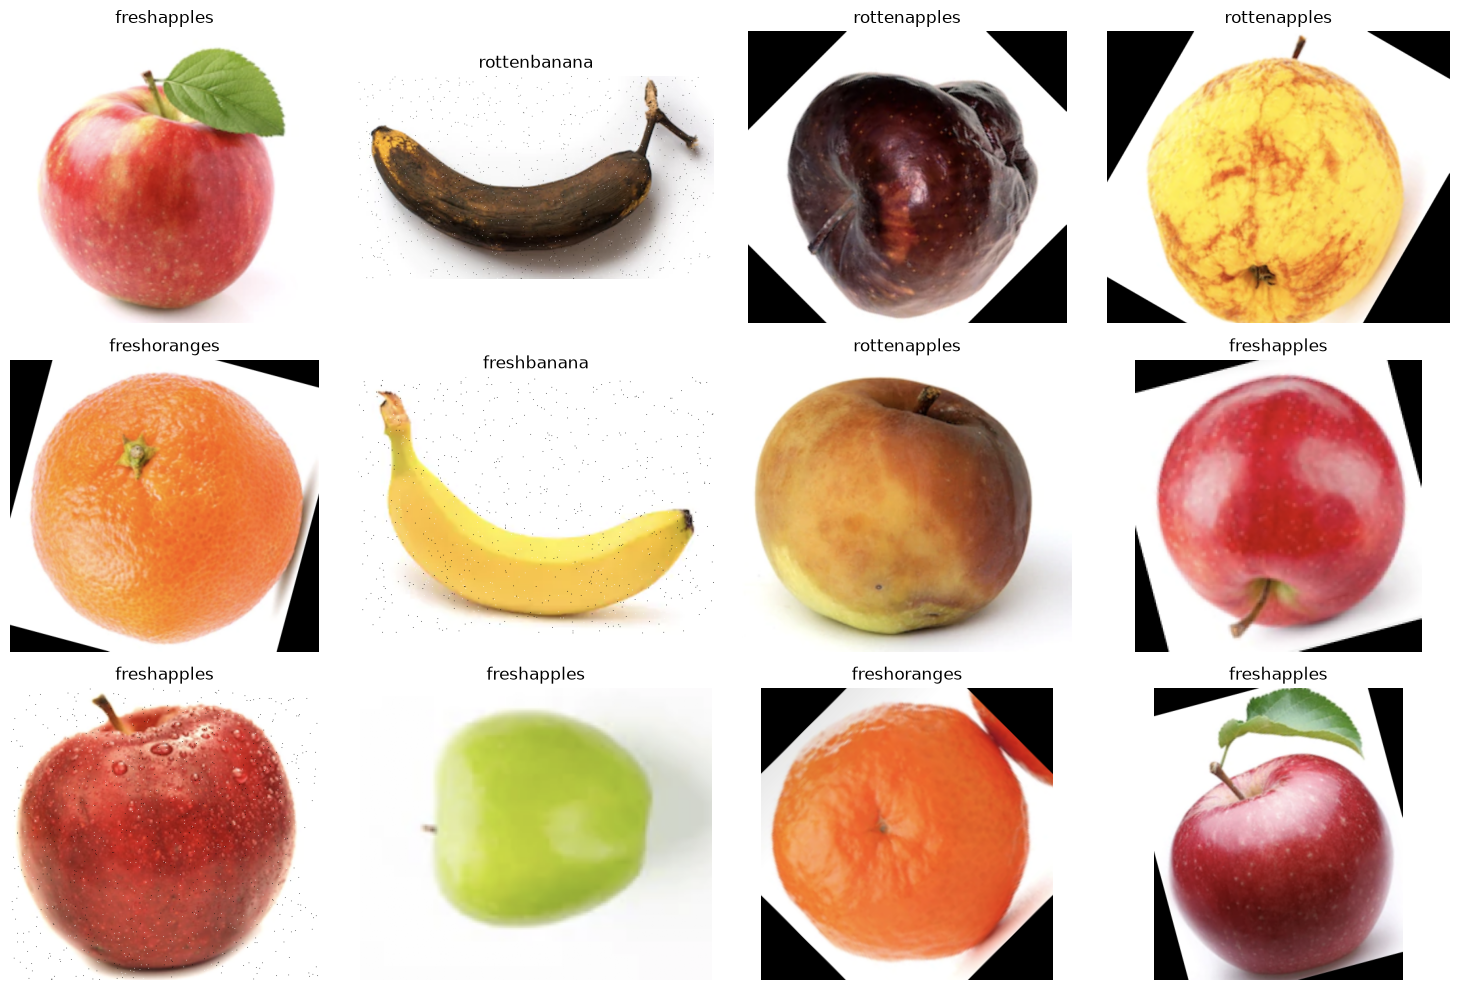

In [25]:
import os
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

test_path = r"fruit_project/dataset/dataset/test"

image_paths = []

for class_name in os.listdir(test_path):

    class_folder = os.path.join(test_path, class_name)

    for file in os.listdir(class_folder):

        if file.endswith((".jpg",".jpeg",".png")):

            image_paths.append(
                (os.path.join(class_folder,file), class_name)
            )

random.shuffle(image_paths)

plt.figure(figsize=(15,10))

for i,(img_path,label) in enumerate(image_paths[:12]):

    img = mpimg.imread(img_path)

    plt.subplot(3,4,i+1)

    plt.imshow(img)

    plt.title(label)

    plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_path = r"fruit_project/dataset/dataset/train"
test_path = r"fruit_project/dataset/dataset/test"

train_gen = ImageDataGenerator(rescale=1./255)

train_dataset = train_gen.flow_from_directory(
    train_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

print(train_dataset.class_indices)


Found 10901 images belonging to 6 classes.
{'freshapples': 0, 'freshbanana': 1, 'freshoranges': 2, 'rottenapples': 3, 'rottenbanana': 4, 'rottenoranges': 5}


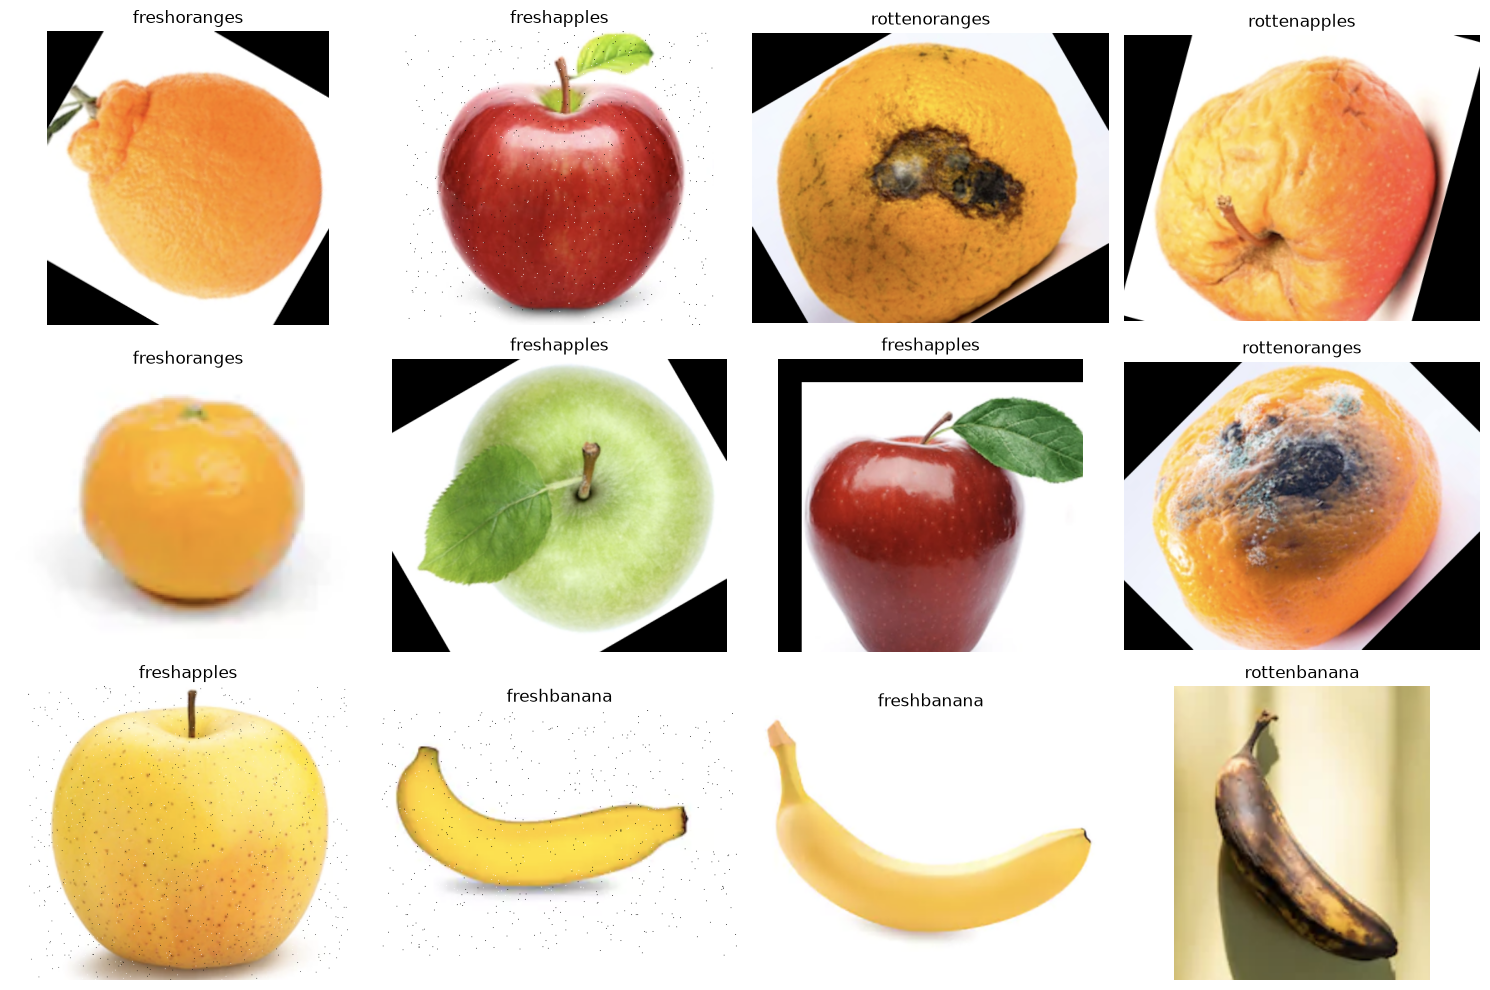

In [28]:
import os
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

test_path = r"fruit_project/dataset/dataset/test"

image_paths = []

for class_name in os.listdir(test_path):

    class_folder = os.path.join(test_path, class_name)

    for file in os.listdir(class_folder):

        if file.endswith((".jpg",".jpeg",".png")):

            image_paths.append(
                (os.path.join(class_folder,file),
                 class_name)
            )

random.shuffle(image_paths)

plt.figure(figsize=(15,10))

for i,(img_path,label) in enumerate(image_paths[:12]):

    img = mpimg.imread(img_path)

    plt.subplot(3,4,i+1)

    plt.imshow(img)
    plt.title(label)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [31]:
print(model.input_shape)
print(img.size)
print(x.shape)

(None, 128, 128, 3)
(224, 224)
(1, 224, 224, 3)


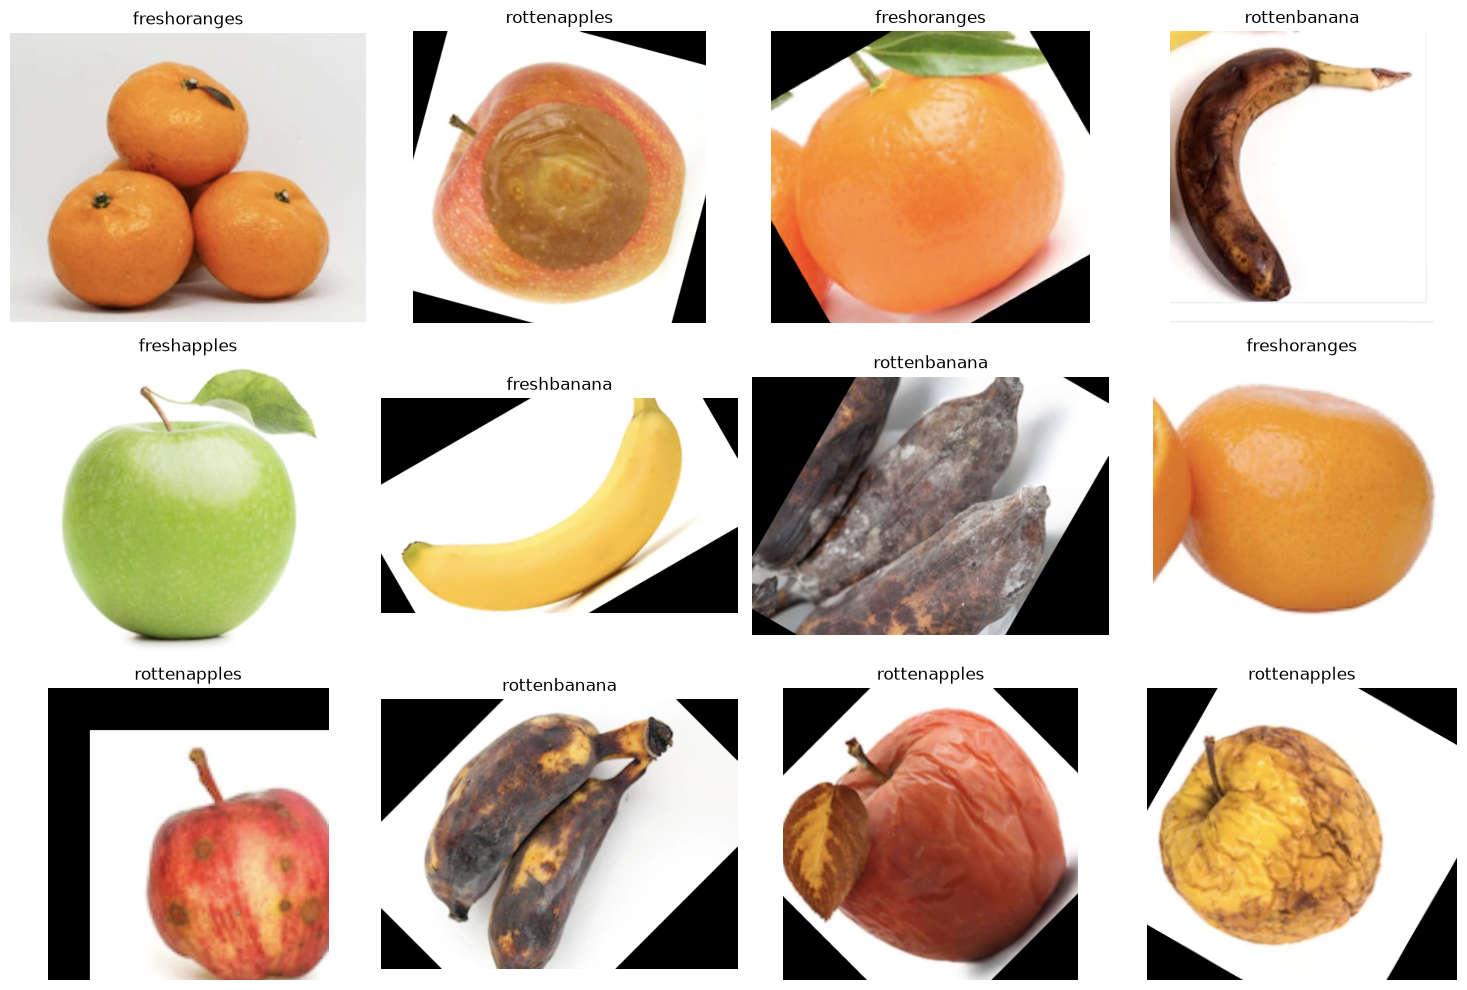

In [34]:
import os
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

dataset_path = r"fruit_project/dataset/dataset/test"

all_images = []

for label in os.listdir(dataset_path):

    label_folder = os.path.join(
        dataset_path,
        label
    )

    for file in os.listdir(label_folder):

        if file.endswith((".png",".jpg",".jpeg")):

            all_images.append(
                (
                    os.path.join(label_folder,file),
                    label
                )
            )

random.shuffle(all_images)

plt.figure(figsize=(15,10))

for i in range(12):

    img_path,label = all_images[i]

    img = mpimg.imread(img_path)

    plt.subplot(3,4,i+1)

    plt.imshow(img)

    plt.title(label)

    plt.axis("off")

plt.tight_layout()

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


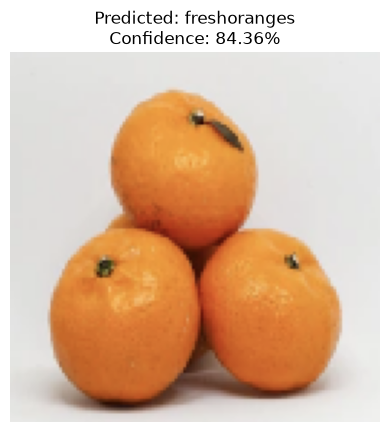

Prediction : freshoranges
Confidence : 84.36 %


In [35]:
import numpy as np
from tensorflow.keras.preprocessing import image

class_names = [
    'freshapples',
    'freshbanana',
    'freshoranges',
    'rottenapples',
    'rottenbanana',
    'rottenoranges'
]

img_path,label = all_images[0]

img = image.load_img(
    img_path,
    target_size=(128,128)
)

x = image.img_to_array(img)

x = np.expand_dims(
    x,
    axis=0
)

x = x/255.0

prediction = model.predict(x)

predicted_label = class_names[
    np.argmax(prediction)
]

confidence = np.max(prediction)*100

plt.imshow(img)

plt.title(
    f"Predicted: {predicted_label}\nConfidence: {confidence:.2f}%"
)

plt.axis("off")

plt.show()

print("Prediction :", predicted_label)
print("Confidence :", round(confidence,2),"%")

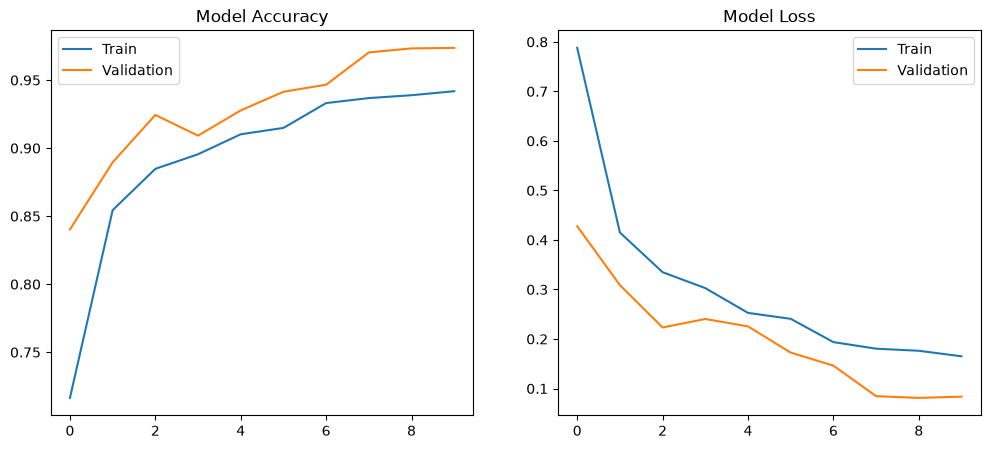

In [36]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Model Accuracy")
plt.legend(['Train','Validation'])

plt.subplot(1,2,2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Model Loss")
plt.legend(['Train','Validation'])

plt.show()